# Proyecto de Análisis de Ventas

## Objetivo

El objetivo de este proyecto es realizar un proceso de exploración, limpieza y análisis de un conjunto de datos de ventas, con el fin de identificar problemas de calidad de los datos, obtener información relevante sobre el comportamiento de las ventas y generar conclusiones que puedan apoyar la toma de decisiones.

El análisis contempla las siguientes etapas:

1. Carga y exploración de los datos.
2. Identificación y tratamiento de valores faltantes.
3. Detección y eliminación de registros duplicados.
4. Limpieza y transformación de variables.
5. Análisis exploratorio de los datos.
6. Visualización de resultados.
7. Obtención de conclusiones.


In [930]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Carga de los datos

Se carga el archivo de ventas en un DataFrame de Pandas para comenzar el proceso de exploración y análisis.


In [931]:
df = pd.read_excel("/content/Datos_Proyecto_Intermedio.xlsx")

In [932]:
df_original = df.copy()

## 2. Exploración inicial de los datos

En esta etapa se realiza una revisión general del conjunto de datos para conocer su estructura, dimensiones, tipos de variables y posibles problemas de calidad.

Se utilizan funciones de Pandas como `head()`, `shape` e `info()` para obtener una primera visión del contenido.


In [933]:
df.head()

,ID_Venta,Fecha,Sucursal,Categoría,Producto,Canal,Vendedor,Cliente_ID,Unidades,Precio_Unitario,Descuento,Costo_Unitario,Metodo_Pago,Estado_Entrega,Total_Venta
0,V-0001,2024-05-20 00:00:00,Santiago Centro,Tecnología,Notebook,Tienda,Diego Muñoz,C-1223,2,479400,20,359800,Tarjeta débito,Entregado,767040
1,V-0002,2024-10-14 00:00:00,Santiago Centro,Belleza,Secador,Online,Fernanda Díaz,C-1348,1,40800,5,23500,Transferencia,Entregado,38760
2,V-0003,2024-06-21 00:00:00,Antofagasta,Hogar,Silla,Tienda,Fernanda Díaz,C-1080,1,44700,10,27400,Transferencia,Entregado,40230
3,V-0004,2024-10-22 00:00:00,Viña del Mar,Belleza,Perfume,Tienda,Fernanda Díaz,C-1284,1,37800,5,27200,Efectivo,Cancelado,0
4,V-0005,2024-07-08 00:00:00,Viña del Mar,Oficina,Archivador,Online,Cristóbal León,C-1388,2,4300,0,2100,Transferencia,Entregado,8600


In [934]:
df.shape

(650, 15)

In [935]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 650 entries, 0 to 649
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   ID_Venta         650 non-null    object
 1   Fecha            649 non-null    object
 2   Sucursal         650 non-null    object
 3   Categoría        649 non-null    object
 4   Producto         648 non-null    object
 5   Canal            649 non-null    object
 6   Vendedor         647 non-null    object
 7   Cliente_ID       650 non-null    object
 8   Unidades         650 non-null    int64 
 9   Precio_Unitario  647 non-null    object
 10  Descuento        650 non-null    object
 11  Costo_Unitario   650 non-null    int64 
 12  Metodo_Pago      649 non-null    object
 13  Estado_Entrega   650 non-null    object
 14  Total_Venta      650 non-null    int64 
dtypes: int64(3), object(12)
memory usage: 76.3+ KB


## 3. Identificación de valores faltantes

Se revisa la presencia de valores faltantes en las diferentes variables del conjunto de datos. Esta revisión permite identificar las columnas que requieren tratamiento antes de realizar el análisis.


In [936]:
df.isnull().sum()

,0
ID_Venta,0
Fecha,1
Sucursal,0
Categoría,1
Producto,2
Canal,1
Vendedor,3
Cliente_ID,0
Unidades,0
Precio_Unitario,3


In [937]:
df[df.isnull().any(axis=1)]

,ID_Venta,Fecha,Sucursal,Categoría,Producto,Canal,Vendedor,Cliente_ID,Unidades,Precio_Unitario,Descuento,Costo_Unitario,Metodo_Pago,Estado_Entrega,Total_Venta
11,V-0012,2024-03-06 00:00:00,Viña del Mar,Belleza,Crema facial,Online,Martina Silva,C-1408,4,NaN,20,4700,Transferencia,Devuelto,0
84,V-0085,NaN,Temuco,Tecnología,Notebook,Marketplace,Cristóbal León,C-1408,4,577600,5,412800,Efectivo,Entregado,2194880
99,V-0100,2024-02-01 00:00:00,Santiago Centro,Belleza,Crema facial,Online,NaN,C-1449,3,13500,0,5400,Tarjeta débito,Entregado,40500
124,V-0125,2024-03-04 00:00:00,Concepción,Deportes,Balón,Tienda,Martina Silva,C-1201,3,NaN,5,8900,Transferencia,Entregado,49875
134,V-0135,2024-11-11 00:00:00,Concepción,Hogar,Organizador,WhatsApp,NaN,C-1377,5,14500,20,7800,Transferencia,Entregado,58000
306,V-0307,2024-07-19 00:00:00,Providencia,Hogar,NaN,WhatsApp,Felipe Torres,C-1514,2,100000,5,59400,Tarjeta crédito,Entregado,190000
309,V-0310,2024-07-11 00:00:00,Viña del Mar,Oficina,NaN,WhatsApp,Felipe Torres,C-1836,4,4000,0,2100,Transferencia,Entregado,16000
316,V-0317,2024-04-27 00:00:00,Providencia,Belleza,Plancha pelo,WhatsApp,Valentina Soto,C-1260,8,53300,10,36300,NaN,Entregado,383760
356,V-0357,2024-06-13 00:00:00,Las Condes,Belleza,Crema facial,Marketplace,Felipe Torres,C-1419,5,NaN,10,5100,Transferencia,Entregado,58050
400,V-0401,2024-04-16 00:00:00,Concepción,Belleza,Secador,Tienda,NaN,C-1384,3,37200,10,25300,Tarjeta débito,Entregado,100440


In [938]:
# Conteo de errores por columna y por tipo, sobre df_original (sin limpiar)
o = df_original
precio_num = pd.to_numeric(o["Precio_Unitario"], errors="coerce")
desc_num = pd.to_numeric(o["Descuento"], errors="coerce")
fecha_ok = pd.to_datetime(o["Fecha"], errors="coerce")

categorias_validas = ["Belleza", "Hogar", "Tecnología", "Deportes", "Oficina"]
canales_validos = ["Tienda", "Online", "WhatsApp", "Marketplace"]
descuentos_validos = [0, 5, 10, 15, 20]

total_formula = precio_num * o["Unidades"] * (1 - desc_num / 100)

resumen_errores = pd.DataFrame([
    ["Valores vacíos", "Fecha", o["Fecha"].isna().sum()],
    ["Valores vacíos", "Categoría", o["Categoría"].isna().sum()],
    ["Valores vacíos", "Producto", o["Producto"].isna().sum()],
    ["Valores vacíos", "Canal", o["Canal"].isna().sum()],
    ["Valores vacíos", "Vendedor", o["Vendedor"].isna().sum()],
    ["Valores vacíos", "Precio_Unitario", o["Precio_Unitario"].isna().sum()],
    ["Valores vacíos", "Metodo_Pago", o["Metodo_Pago"].isna().sum()],
    ["Formato incorrecto", "Fecha (texto o fecha imposible: 31/02, mes 13)", (fecha_ok.isna() & o["Fecha"].notna()).sum()],
    ["Formato incorrecto", "Precio_Unitario (texto: '$58.700', 'precio pendiente')", o["Precio_Unitario"].map(lambda x: isinstance(x, str)).sum()],
    ["Formato incorrecto", "Descuento (texto: '10%')", o["Descuento"].map(lambda x: isinstance(x, str)).sum()],
    ["Error de escritura", "Categoría (BELLEZA, Deporte, Tecno, Oficna)", (o["Categoría"].notna() & ~o["Categoría"].isin(categorias_validas)).sum()],
    ["Error de escritura", "Producto (mayúsculas/minúsculas)", (o["Producto"].notna() & (o["Producto"] != o["Producto"].str.capitalize())).sum()],
    ["Error de escritura", "Canal (TIENDA, On line, Market place...)", (o["Canal"].notna() & ~o["Canal"].isin(canales_validos)).sum()],
    ["Fuera de rango", "Precio_Unitario = 1", (precio_num == 1).sum()],
    ["Fuera de rango", "Precio_Unitario = 9.999.999", (precio_num == 9999999).sum()],
    ["Fuera de rango", "Descuento distinto de 0/5/10/15/20 (80, 55, -5)", (desc_num.notna() & ~desc_num.isin(descuentos_validos)).sum()],
    ["Fuera de rango", "Unidades negativas", (o["Unidades"] < 0).sum()],
    ["Fuera de rango", "Unidades = 0", (o["Unidades"] == 0).sum()],
    ["Inconsistencia", "Total_Venta distinto de Precio x Unidades x (1 - Descuento)", ((total_formula - o["Total_Venta"]).abs() > 1).sum()],
    ["Duplicados", "Filas duplicadas exactas", o.duplicated().sum()],
], columns=["Tipo de error", "Columna / detalle", "Filas afectadas"])

resumen_errores

,Tipo de error,Columna / detalle,Filas afectadas
0,Valores vacíos,Fecha,1
1,Valores vacíos,Categoría,1
2,Valores vacíos,Producto,2
3,Valores vacíos,Canal,1
4,Valores vacíos,Vendedor,3
5,Valores vacíos,Precio_Unitario,3
6,Valores vacíos,Metodo_Pago,1
7,Formato incorrecto,"Fecha (texto o fecha imposible: 31/02, mes 13)",5
8,Formato incorrecto,"Precio_Unitario (texto: '$58.700', 'precio pen...",3
9,Formato incorrecto,Descuento (texto: '10%'),3


## 4. Detección y eliminación de registros duplicados

Se verifica la existencia de registros duplicados para evitar que una misma venta sea contabilizada más de una vez durante el análisis.

Se identificaron 4 registros duplicados exactos, los cuales fueron eliminados para mantener un único registro por venta.


In [939]:
df.duplicated().sum()

np.int64(4)

In [940]:
df[df.duplicated(keep=False)]

,ID_Venta,Fecha,Sucursal,Categoría,Producto,Canal,Vendedor,Cliente_ID,Unidades,Precio_Unitario,Descuento,Costo_Unitario,Metodo_Pago,Estado_Entrega,Total_Venta
33,V-0034,2024-03-09 00:00:00,Antofagasta,Tecnología,Teclado,WhatsApp,Cristóbal León,C-1918,5,23800,10,14500,Tarjeta débito,Cancelado,0
34,V-0034,2024-03-09 00:00:00,Antofagasta,Tecnología,Teclado,WhatsApp,Cristóbal León,C-1918,5,23800,10,14500,Tarjeta débito,Cancelado,0
569,V-0570,2024-02-28 00:00:00,Viña del Mar,Deportes,Botella deportiva,Tienda,Martina Silva,C-1567,2,7300,0,3600,Tarjeta crédito,Entregado,14600
570,V-0570,2024-02-28 00:00:00,Viña del Mar,Deportes,Botella deportiva,Tienda,Martina Silva,C-1567,2,7300,0,3600,Tarjeta crédito,Entregado,14600
586,V-0587,2024-10-20 00:00:00,Las Condes,Belleza,Crema facial,Online,Valentina Soto,C-1816,1,12400,15,4900,Tarjeta crédito,Entregado,10540
587,V-0587,2024-10-20 00:00:00,Las Condes,Belleza,Crema facial,Online,Valentina Soto,C-1816,1,12400,15,4900,Tarjeta crédito,Entregado,10540
616,V-0617,2024-03-04 00:00:00,Antofagasta,Hogar,Mesa,Marketplace,Valentina Soto,C-1221,3,89800,0,51400,Tarjeta crédito,Entregado,269400
617,V-0617,2024-03-04 00:00:00,Antofagasta,Hogar,Mesa,Marketplace,Valentina Soto,C-1221,3,89800,0,51400,Tarjeta crédito,Entregado,269400


In [941]:
df = df.drop_duplicates()

In [942]:
df.duplicated().sum()

np.int64(0)

In [943]:
print("Duplicados:", df.duplicated().sum())
print("Dimensiones:", df.shape)

Duplicados: 0
Dimensiones: (646, 15)


## 5. Limpieza de `Precio_Unitario`

Durante la exploración se detectó que la variable `Precio_Unitario` presentaba diferentes formatos y valores inconsistentes. La columna contenía valores numéricos, precios almacenados como texto con símbolos monetarios, valores faltantes y el registro `"precio pendiente"`.

Se realizó una revisión de los valores existentes y posteriormente se transformó la variable a formato numérico.

Para los registros con precio faltante se utilizó la información disponible en otras variables de la venta. En el caso de la venta devuelta, donde no era posible obtener el precio a partir del total, se utilizó la mediana de los precios registrados para el mismo producto.

Finalmente, se verificó que no quedaran valores nulos en la variable.


In [944]:
df["Precio_Unitario"].unique()

array([479400, 40800, 44700, 37800, 4300, 13300, 16100, 17100, 37100,
       20000, 33700, nan, 6700, 11600, 17800, 41500, 148500, 49200, 85600,
       3800, 48100, 99200, 21600, 35100, 3700, 32700, 17600, 90900, 18700,
       42000, 162700, 8100, 23800, 93800, 58800, 3500, 35200, 17000, 4700,
       18400, 3000, 2200, 57200, 59000, 12000, 29700, 3900, 41300, 87900,
       8800, 41700, 45600, 12900, 4500, 18000, 53800, 8000, 18500, 34300,
       11900, 51200, 91100, 3100, 19900, 10500, 14300, 45700, 49300,
       49800, 1, 9900, 478800, 2500, 23600, 11100, 2900, 7300, 577600,
       11500, 18900, 11400, 141000, 96500, 12300, 46500, 485000, 2400,
       98100, 52400, 24600, 2800, 13500, 12200, 11700, 3600, 106200,
       '$58.700', 40000, 8400, 83200, 38000, 31900, 581400, 19500, 14000,
       46300, 7500, 10900, 155700, 34600, 15800, 46900, 92800, 44200,
       27400, 59800, 18600, 23000, 46400, 14500, 25300, 49100, 141700,
       50100, 45500, 3300, 8300, 24300, 53100, 520800, 38400, 

In [945]:
df[df["Precio_Unitario"].isin(["$58.700", "$59.600", "precio pendiente", 9999999])]

,ID_Venta,Fecha,Sucursal,Categoría,Producto,Canal,Vendedor,Cliente_ID,Unidades,Precio_Unitario,Descuento,Costo_Unitario,Metodo_Pago,Estado_Entrega,Total_Venta
104,V-0105,2024-03-19 00:00:00,Temuco,Belleza,Plancha pelo,Marketplace,Ignacio Pérez,C-1992,1,$58.700,0,36400,Efectivo,Entregado,58700
484,V-0485,2024-11-04 00:00:00,Concepción,Tecnología,Notebook,Marketplace,Felipe Torres,C-1164,1,9999999,10,366900,Tarjeta débito,Entregado,538380
494,V-0495,2024-06-10 00:00:00,Las Condes,Deportes,Botella deportiva,WhatsApp,Fernanda Díaz,C-1137,6,precio pendiente,0,3200,Transferencia,Entregado,45600
640,V-0641,2024-06-21 00:00:00,Temuco,Belleza,Plancha pelo,WhatsApp,Camila Rojas,C-1998,2,$59.600,5,38100,Transferencia,Cancelado,0


In [946]:
# Los precios guardados como texto ("$58.700", "$59.600") se convierten a número quitando "$" y "."
# (separador de miles). "precio pendiente" no es convertible, por lo que queda como NaN.
df["Precio_Unitario"] = pd.to_numeric(
    df["Precio_Unitario"].map(lambda x: x.replace("$", "").replace(".", "") if isinstance(x, str) else x),
    errors="coerce"
)

In [947]:
df["Precio_Unitario"].dtype

dtype('float64')

In [948]:
df["Precio_Unitario"].isnull().sum()

np.int64(4)

In [949]:
df[df["Precio_Unitario"].isnull()]

,ID_Venta,Fecha,Sucursal,Categoría,Producto,Canal,Vendedor,Cliente_ID,Unidades,Precio_Unitario,Descuento,Costo_Unitario,Metodo_Pago,Estado_Entrega,Total_Venta
11,V-0012,2024-03-06 00:00:00,Viña del Mar,Belleza,Crema facial,Online,Martina Silva,C-1408,4,NaN,20,4700,Transferencia,Devuelto,0
124,V-0125,2024-03-04 00:00:00,Concepción,Deportes,Balón,Tienda,Martina Silva,C-1201,3,NaN,5,8900,Transferencia,Entregado,49875
356,V-0357,2024-06-13 00:00:00,Las Condes,Belleza,Crema facial,Marketplace,Felipe Torres,C-1419,5,NaN,10,5100,Transferencia,Entregado,58050
494,V-0495,2024-06-10 00:00:00,Las Condes,Deportes,Botella deportiva,WhatsApp,Fernanda Díaz,C-1137,6,NaN,0,3200,Transferencia,Entregado,45600


In [950]:
df[df["Producto"].isin(["Crema facial", "Balón", "Botella deportiva"])][
    ["Producto", "Precio_Unitario"]
].sort_values("Producto")

,Producto,Precio_Unitario
643,Balón,20900.0
517,Balón,16900.0
166,Balón,18100.0
513,Balón,16800.0
332,Balón,20500.0
...,...,...
467,Crema facial,13900.0
189,Crema facial,11600.0
187,Crema facial,12000.0
171,Crema facial,12000.0


In [951]:
df[df["Producto"] == "Crema facial"]["Precio_Unitario"].median()

12350.0

In [952]:
# Imputación de los 4 precios faltantes. Se identifica cada venta por su ID_Venta
precios_imputados = {
    "V-0012": 12350,  # Mediana de precios de "Crema facial": el total no permite recuperar el precio
    "V-0125": 17500,  # Precio recuperado desde Total_Venta, Unidades y Descuento de la misma venta
    "V-0357": 12900,  # Precio recuperado desde Total_Venta, Unidades y Descuento de la misma venta
    "V-0495": 7600,   # Precio recuperado desde Total_Venta, Unidades y Descuento de la misma venta
}

for venta, precio in precios_imputados.items():
    df.loc[df["ID_Venta"] == venta, "Precio_Unitario"] = precio

In [953]:
df["Precio_Unitario"].isnull().sum()

np.int64(0)

## 6. Limpieza y transformación de la variable `Fecha`

Se revisa la variable `Fecha` para identificar su formato actual, valores faltantes o posibles inconsistencias. Posteriormente, se transformará a un formato de fecha adecuado para facilitar el análisis temporal de las ventas.


In [954]:
df["Fecha"].unique()

array([datetime.datetime(2024, 5, 20, 0, 0),
       datetime.datetime(2024, 10, 14, 0, 0),
       datetime.datetime(2024, 6, 21, 0, 0),
       datetime.datetime(2024, 10, 22, 0, 0),
       datetime.datetime(2024, 7, 8, 0, 0),
       datetime.datetime(2024, 12, 16, 0, 0),
       datetime.datetime(2024, 7, 21, 0, 0),
       datetime.datetime(2024, 2, 16, 0, 0),
       datetime.datetime(2024, 10, 10, 0, 0),
       datetime.datetime(2024, 5, 14, 0, 0),
       datetime.datetime(2024, 11, 2, 0, 0),
       datetime.datetime(2024, 3, 6, 0, 0),
       datetime.datetime(2024, 3, 2, 0, 0),
       datetime.datetime(2024, 2, 6, 0, 0),
       datetime.datetime(2024, 2, 19, 0, 0),
       datetime.datetime(2024, 4, 7, 0, 0),
       datetime.datetime(2024, 3, 26, 0, 0),
       datetime.datetime(2024, 3, 20, 0, 0),
       datetime.datetime(2024, 2, 11, 0, 0),
       datetime.datetime(2024, 12, 8, 0, 0),
       datetime.datetime(2024, 3, 8, 0, 0),
       datetime.datetime(2024, 2, 29, 0, 0),
       datet

In [955]:
df[df["Fecha"].astype(str).isin(["nan", "sin fecha", "31/02/2024", "15-15-2024", "2024-13-05"])]

,ID_Venta,Fecha,Sucursal,Categoría,Producto,Canal,Vendedor,Cliente_ID,Unidades,Precio_Unitario,Descuento,Costo_Unitario,Metodo_Pago,Estado_Entrega,Total_Venta
84,V-0085,NaN,Temuco,Tecnología,Notebook,Marketplace,Cristóbal León,C-1408,4,577600.0,5,412800,Efectivo,Entregado,2194880
223,V-0224,31/02/2024,Las Condes,Tecnología,Teclado,Tienda,Camila Rojas,C-1063,3,23000.0,0,12000,Tarjeta débito,Pendiente,69000
230,V-0231,31/02/2024,Las Condes,Hogar,Silla,Online,Cristóbal León,C-1555,2,49600.0,0,27400,Transferencia,Entregado,99200
370,V-0371,sin fecha,Concepción,Deportes,Botella deportiva,WhatsApp,Felipe Torres,C-1701,3,7900.0,20,3900,Tarjeta crédito,Entregado,18960
444,V-0445,15-15-2024,Temuco,Hogar,Organizador,Online,Camila Rojas,C-1900,4,15700.0,0,8000,Efectivo,Entregado,62800
594,V-0595,2024-13-05,La Serena,Hogar,Organizador,Marketplace,Fernanda Díaz,C-1651,1,13800.0,5,8800,Tarjeta débito,Entregado,13110


In [956]:
# Las fechas inválidas ("31/02/2024", "15-15-2024", "2024-13-05", "sin fecha") se convierten a NaT
df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")

In [957]:
df["Fecha"].isnull().sum()

np.int64(6)

### Tratamiento de fechas inválidas

Se identificaron 6 registros con fechas faltantes o inválidas, los cuales fueron convertidos a `NaT` mediante `pd.to_datetime(errors="coerce")`.

Dado que no existe información suficiente para recuperar las fechas originales, estos registros se conservarán en el dataset y se excluirán únicamente de los análisis temporales.

**Impacto:** 6 registros, equivalentes al 0,93% del dataset, con ventas asociadas por $2.457.950.


In [958]:
df[df["Fecha"].isnull()][["ID_Venta", "Fecha", "Total_Venta", "Estado_Entrega"]]

,ID_Venta,Fecha,Total_Venta,Estado_Entrega
84,V-0085,NaT,2194880,Entregado
223,V-0224,NaT,69000,Pendiente
230,V-0231,NaT,99200,Entregado
370,V-0371,NaT,18960,Entregado
444,V-0445,NaT,62800,Entregado
594,V-0595,NaT,13110,Entregado


In [959]:
df[df["Fecha"].isnull()]["Total_Venta"].sum()

np.int64(2457950)

In [960]:
df["Fecha"].dtype

dtype('<M8[ns]')

## 7. Identificación de valores faltantes en variables categóricas

Se revisarán las variables categóricas para identificar registros con información faltante y determinar el tratamiento más adecuado para cada caso.


In [961]:
df[df[["Categoría", "Producto", "Canal", "Vendedor", "Metodo_Pago"]].isnull().any(axis=1)]

,ID_Venta,Fecha,Sucursal,Categoría,Producto,Canal,Vendedor,Cliente_ID,Unidades,Precio_Unitario,Descuento,Costo_Unitario,Metodo_Pago,Estado_Entrega,Total_Venta
99,V-0100,2024-02-01,Santiago Centro,Belleza,Crema facial,Online,NaN,C-1449,3,13500.0,0,5400,Tarjeta débito,Entregado,40500
134,V-0135,2024-11-11,Concepción,Hogar,Organizador,WhatsApp,NaN,C-1377,5,14500.0,20,7800,Transferencia,Entregado,58000
306,V-0307,2024-07-19,Providencia,Hogar,NaN,WhatsApp,Felipe Torres,C-1514,2,100000.0,5,59400,Tarjeta crédito,Entregado,190000
309,V-0310,2024-07-11,Viña del Mar,Oficina,NaN,WhatsApp,Felipe Torres,C-1836,4,4000.0,0,2100,Transferencia,Entregado,16000
316,V-0317,2024-04-27,Providencia,Belleza,Plancha pelo,WhatsApp,Valentina Soto,C-1260,8,53300.0,10,36300,NaN,Entregado,383760
400,V-0401,2024-04-16,Concepción,Belleza,Secador,Tienda,NaN,C-1384,3,37200.0,10,25300,Tarjeta débito,Entregado,100440
455,V-0456,2024-09-15,Providencia,Tecnología,Teclado,NaN,Fernanda Díaz,C-1972,1,22900.0,0,13100,Tarjeta débito,Entregado,22900
631,V-0632,2024-07-10,Providencia,NaN,Botella deportiva,WhatsApp,Valentina Soto,C-1198,2,7300.0,0,3900,Efectivo,Entregado,14600


In [962]:
for columna in ["Categoría", "Producto", "Canal", "Vendedor", "Metodo_Pago"]:
    print(f"\n--- {columna} ---")
    print(df.groupby(columna, dropna=False)["Total_Venta"].count().sort_values(ascending=False).head(10))


--- Categoría ---
Categoría
Hogar         134
Belleza       131
Tecnología    129
Deportes      127
Oficina       117
BELLEZA         4
Deporte         1
Oficna          1
Tecno           1
NaN             1
Name: Total_Venta, dtype: int64

--- Producto ---
Producto
Botella deportiva    44
Plancha pelo         40
Silla                39
Set lápices          37
Lámpara              36
Crema facial         36
Organizador          32
Notebook             31
Secador              30
Balón                30
Name: Total_Venta, dtype: int64

--- Canal ---
Canal
Tienda          180
Online          160
WhatsApp        154
Marketplace     141
TIENDA            3
Market place      2
On line           2
Whatsapp          2
online            1
NaN               1
Name: Total_Venta, dtype: int64

--- Vendedor ---
Vendedor
Cristóbal León    98
Fernanda Díaz     98
Felipe Torres     82
Diego Muñoz       81
Camila Rojas      77
Ignacio Pérez     70
Valentina Soto    70
Martina Silva     67
NaN         

In [963]:
# Se unifican variantes de escritura (mayúsculas, espacios, errores de tipeo)
df["Categoría"] = df["Categoría"].replace({
    "BELLEZA": "Belleza",
    "Deporte": "Deportes",
    "Oficna": "Oficina",
    "Tecno": "Tecnología"
})

df["Canal"] = df["Canal"].replace({
    "TIENDA": "Tienda",
    "Market place": "Marketplace",
    "On line": "Online",
    "Whatsapp": "WhatsApp",
    "online": "Online"
})

df["Producto"] = df["Producto"].replace({
    "mancuernas": "Mancuernas",
    "balón": "Balón",
    "TECLADO": "Teclado",
    "MANCUERNAS": "Mancuernas",
    "notebook": "Notebook",
    "colchoneta": "Colchoneta",
    "botella deportiva": "Botella deportiva",
    "MONITOR": "Monitor"
})

In [964]:
df["Producto"].value_counts(dropna=False)

,count
Producto,
Botella deportiva,45
Plancha pelo,40
Silla,39
Set lápices,37
Lámpara,36
Crema facial,36
Organizador,32
Notebook,32
Mancuernas,31


In [965]:
print(df["Categoría"].value_counts(dropna=False))
print("\n", df["Canal"].value_counts(dropna=False))

Categoría
Belleza       135
Hogar         134
Tecnología    130
Deportes      128
Oficina       118
NaN             1
Name: count, dtype: int64

 Canal
Tienda         183
Online         163
WhatsApp       156
Marketplace    143
NaN              1
Name: count, dtype: int64


In [966]:
df[df["Producto"] == "Botella deportiva"][["Producto", "Categoría"]].value_counts(dropna=False)

Producto           Categoría
Botella deportiva  Deportes     44
                   NaN           1
Name: count, dtype: int64

In [967]:
# "Botella deportiva" siempre pertenece a la categoría Deportes: se completa la categoría faltante
df.loc[df["Producto"] == "Botella deportiva", "Categoría"] = "Deportes"

In [968]:
df["Categoría"].isnull().sum()

np.int64(0)

In [969]:
df[df["Producto"].isin(["Organizador", "Teclado"])][
    ["Producto", "Sucursal", "Vendedor", "Canal"]
].value_counts(dropna=False)

Producto     Sucursal         Vendedor        Canal      
Teclado      Las Condes       Cristóbal León  Marketplace    2
             La Serena        Diego Muñoz     Online         2
Organizador  Antofagasta      Fernanda Díaz   Online         1
             Concepción       Felipe Torres   Online         1
                                              Tienda         1
                              Fernanda Díaz   WhatsApp       1
                              NaN             WhatsApp       1
             La Serena        Camila Rojas    Tienda         1
             Antofagasta      Diego Muñoz     Tienda         1
                              Felipe Torres   Marketplace    1
             Las Condes       Camila Rojas    Online         1
                                              Tienda         1
                              Cristóbal León  Marketplace    1
                                              Tienda         1
                              Fernanda Díaz   Marketplace    1
             Providencia      Diego Muñoz     Online         1
                                              Tienda         1
                              Felipe Torres   Tienda         1
                              Fernanda Díaz   Marketplace    1
                              Valentina Soto  Marketplace    1
             Santiago Centro  Camila Rojas    Online         1
                              Cristóbal León  Online         1
                              Diego Muñoz     Online         1
                              Felipe Torres   WhatsApp       1
             La Serena        Cristóbal León  WhatsApp       1
                              Fernanda Díaz   Marketplace    1
             Temuco           Camila Rojas    Tienda         1
                                              Online         1
                              Ignacio Pérez   WhatsApp       1
                              Felipe Torres   Marketplace    1
             Viña del Mar     Felipe Torres   Online         1
                              Martina Silva   Tienda         1
Teclado      Antofagasta      Camila Rojas    WhatsApp       1
Organizador  Temuco           Fernanda Díaz   Tienda         1
Teclado      Antofagasta      Cristóbal León  WhatsApp       1
                              Fernanda Díaz   WhatsApp       1
             Concepción       Felipe Torres   Tienda         1
                              Cristóbal León  Tienda         1
             La Serena        Camila Rojas    Online         1
                              Cristóbal León  Marketplace    1
                              Fernanda Díaz   Online         1
Organizador  Viña del Mar     Camila Rojas    Online         1
Teclado      Las Condes       Camila Rojas    Tienda         1
             Providencia      Fernanda Díaz   NaN            1
             Santiago Centro  Camila Rojas    Marketplace    1
                                              Tienda         1
                              Cristóbal León  Online         1
                              Felipe Torres   Tienda         1
                              Valentina Soto  Tienda         1
             Temuco           Diego Muñoz     Tienda         1
                              Felipe Torres   Marketplace    1
                                              WhatsApp       1
                              Fernanda Díaz   Online         1
             Viña del Mar     Cristóbal León  Tienda         1
                              Diego Muñoz     Marketplace    1
                              Felipe Torres   WhatsApp       1
                              Ignacio Pérez   Online         1
                                              Tienda         1
Name: count, dtype: int64

In [970]:
df[df["Vendedor"].isnull()][
    ["ID_Venta", "Sucursal", "Categoría", "Producto", "Canal", "Cliente_ID"]
]

,ID_Venta,Sucursal,Categoría,Producto,Canal,Cliente_ID
99,V-0100,Santiago Centro,Belleza,Crema facial,Online,C-1449
134,V-0135,Concepción,Hogar,Organizador,WhatsApp,C-1377
400,V-0401,Concepción,Belleza,Secador,Tienda,C-1384


In [971]:
df[
    (df["Producto"].isin(["Crema facial", "Organizador", "Secador"])) &
    (df["Sucursal"].isin(["Santiago Centro", "Concepción"])) &
    (df["Canal"].isin(["Online", "WhatsApp", "Tienda"]))
][["Sucursal", "Producto", "Canal", "Vendedor"]].value_counts(dropna=False)

Sucursal         Producto      Canal     Vendedor      
Concepción       Secador       WhatsApp  Cristóbal León    2
                 Crema facial  Online    Valentina Soto    1
                 Organizador   Online    Felipe Torres     1
                               Tienda    Felipe Torres     1
                               WhatsApp  NaN               1
                                         Fernanda Díaz     1
                 Secador       Tienda    Ignacio Pérez     1
                                         NaN               1
                               WhatsApp  Fernanda Díaz     1
Santiago Centro  Crema facial  Online    NaN               1
                               Tienda    Fernanda Díaz     1
                 Organizador   Online    Camila Rojas      1
                                         Cristóbal León    1
                                         Diego Muñoz       1
                               WhatsApp  Felipe Torres     1
                 Secador       Online    Fernanda Díaz     1
                               WhatsApp  Camila Rojas      1
                                         Fernanda Díaz     1
Name: count, dtype: int64

In [972]:
df[df["ID_Venta"] == "V-0317"][
    ["Producto", "Canal", "Vendedor", "Metodo_Pago"]
]

,Producto,Canal,Vendedor,Metodo_Pago
316,Plancha pelo,WhatsApp,Valentina Soto,NaN


In [973]:
df[(df["Producto"] == "Plancha pelo") & (df["Canal"] == "WhatsApp")][
    ["Producto", "Canal", "Vendedor", "Metodo_Pago"]
].value_counts(dropna=False)

Producto      Canal     Vendedor        Metodo_Pago   
Plancha pelo  WhatsApp  Camila Rojas    Transferencia     2
                        Cristóbal León  Transferencia     2
                        Diego Muñoz     Tarjeta débito    1
                        Felipe Torres   Efectivo          1
                                        Transferencia     1
                        Fernanda Díaz   Efectivo          1
                        Ignacio Pérez   Tarjeta débito    1
                        Valentina Soto  Tarjeta débito    1
                                        NaN               1
Name: count, dtype: int64

In [974]:
df[df["Producto"].isnull()][
    ["ID_Venta", "Categoría", "Canal", "Vendedor", "Cliente_ID"]
]

,ID_Venta,Categoría,Canal,Vendedor,Cliente_ID
306,V-0307,Hogar,WhatsApp,Felipe Torres,C-1514
309,V-0310,Oficina,WhatsApp,Felipe Torres,C-1836


In [975]:
df.isnull().sum()

,0
ID_Venta,0
Fecha,6
Sucursal,0
Categoría,0
Producto,2
Canal,1
Vendedor,3
Cliente_ID,0
Unidades,0
Precio_Unitario,0


In [976]:
# Sin información suficiente para imputar de forma confiable: se marca explícitamente como "Sin (item reemplazado)"
df["Categoría"] = df["Categoría"].fillna("Sin categoría")
df["Producto"] = df["Producto"].fillna("Sin producto")
df["Canal"] = df["Canal"].fillna("Sin canal")
df["Vendedor"] = df["Vendedor"].fillna("Sin vendedor")
df["Metodo_Pago"] = df["Metodo_Pago"].fillna("Sin método de pago")

In [977]:
df.isnull().sum()

,0
ID_Venta,0
Fecha,6
Sucursal,0
Categoría,0
Producto,0
Canal,0
Vendedor,0
Cliente_ID,0
Unidades,0
Precio_Unitario,0


### Tratamiento de valores faltantes

Luego de la revisión y limpieza, las variables categóricas quedaron sin valores faltantes. Los registros que no contaban con información suficiente para realizar una imputación confiable fueron rotulados como **"Sin producto"**, **"Sin canal"**, **"Sin vendedor"** y **"Sin método de pago"**, evitando introducir información no respaldada por los datos.

La única excepción es la categoría vacía de la venta **V-0632**: su producto es *Botella deportiva*, que en todos los demás registros pertenece a *Deportes*, por lo que se completó con esa categoría. Aun así, la venta queda marcada como originalmente vacía y se excluye de los gráficos.

La variable `Fecha` mantiene **6 registros como `NaT`**, correspondientes a fechas faltantes o inválidas que no pudieron ser recuperadas.

Con esto, finaliza la etapa de tratamiento de valores faltantes.


In [978]:
df["Precio_Unitario"].describe()

,Precio_Unitario
count,6.460000e+02
mean,7.198259e+04
std,4.067547e+05
min,1.000000e+00
25%,1.132500e+04
50%,1.890000e+04
75%,4.775000e+04
max,9.999999e+06


In [979]:
df.nlargest(10, "Precio_Unitario")[[
    "ID_Venta",
    "Producto",
    "Unidades",
    "Precio_Unitario",
    "Descuento",
    "Total_Venta"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta
484,V-0485,Notebook,1,9999999.0,10,538380
476,V-0477,Notebook,3,609000.0,10,1644300
583,V-0584,Notebook,2,596500.0,0,1193000
165,V-0166,Notebook,2,589000.0,0,1178000
240,V-0241,Notebook,3,588600.0,10,1589220
296,V-0297,Notebook,1,581500.0,5,0
110,V-0111,Notebook,2,581400.0,0,1162800
84,V-0085,Notebook,4,577600.0,5,2194880
621,V-0622,Notebook,-1,577300.0,0,1154600
615,V-0616,Notebook,4,568900.0,15,1934260


In [980]:
df[df["ID_Venta"].isin(["V-0485", "V-0297", "V-0622"])][[
    "ID_Venta",
    "Producto",
    "Unidades",
    "Precio_Unitario",
    "Descuento",
    "Total_Venta",
    "Estado_Entrega"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
296,V-0297,Notebook,1,581500.0,5,0,Devuelto
484,V-0485,Notebook,1,9999999.0,10,538380,Entregado
621,V-0622,Notebook,-1,577300.0,0,1154600,Entregado


In [981]:
df[df["Unidades"] < 0][[
    "ID_Venta",
    "Producto",
    "Unidades",
    "Precio_Unitario",
    "Descuento",
    "Total_Venta",
    "Estado_Entrega"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
140,V-0141,Set lápices,-3,3300.0,20,5280,Entregado
391,V-0392,Botella deportiva,-1,8000.0,20,6400,Entregado
432,V-0433,Secador,-3,34400.0,10,247680,Entregado
468,V-0469,Set lápices,-1,3500.0,0,31500,Pendiente
527,V-0528,Botella deportiva,-1,7200.0,10,0,Cancelado
621,V-0622,Notebook,-1,577300.0,0,1154600,Entregado


In [982]:
df["Descuento"].value_counts(dropna=False)

,count
Descuento,
0,212
5,153
10,123
15,85
20,65
10%,3
80,2
-5,2
55,1


In [983]:
df[df["Descuento"].isin([80, -5, 55])][[
    "ID_Venta",
    "Producto",
    "Unidades",
    "Precio_Unitario",
    "Descuento",
    "Total_Venta",
    "Estado_Entrega"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
246,V-0247,Plancha pelo,2,50100.0,80,100200,Pendiente
298,V-0299,Calculadora,1,12200.0,-5,10980,Pendiente
401,V-0402,Plancha pelo,4,59200.0,-5,213120,Entregado
627,V-0628,Silla,3,45400.0,55,136200,Entregado
634,V-0635,Balón,7,20600.0,80,129780,Entregado


In [984]:
df["Descuento"].unique()

array([20, 5, 10, 0, 15, '10%', 80, -5, 55], dtype=object)

In [985]:
# Descuento viene mezclado: números y el texto "10%". Se quita el "%" y se convierte todo a número.
df["Descuento"] = pd.to_numeric(
    df["Descuento"].map(lambda x: x.replace("%", "") if isinstance(x, str) else x)
)

In [986]:
df["Descuento"].unique()

array([20,  5, 10,  0, 15, 80, -5, 55])

In [987]:
df.groupby("Producto")["Descuento"].unique()

,Descuento
Producto,
Archivador,"[0, 5, 15, 10, 20]"
Balón,"[0, 5, 10, 20, 15, 80]"
Botella deportiva,"[20, 0, 5, 15, 10]"
Calculadora,"[15, 0, 5, 10, -5]"
Colchoneta,"[15, 10, 20, 5, 0]"
Crema facial,"[0, 20, 5, 10, 15]"
Cuaderno,"[15, 10, 20, 0, 5]"
Impresora,"[5, 10, 0, 15]"
Lámpara,"[0, 5, 10, 20, 15]"


In [988]:
# Los descuentos válidos de la empresa son 0, 5, 10, 15 y 20 %. Cualquier otro valor se marca como anómalo.
df["Descuento_Anomalo"] = ~df["Descuento"].isin([0, 5, 10, 15, 20])

In [989]:
df["Descuento_Anomalo"].value_counts()

,count
Descuento_Anomalo,
False,641
True,5


In [990]:
df.loc[df["Descuento_Anomalo"], [
    "ID_Venta", "Producto", "Unidades",
    "Precio_Unitario", "Descuento", "Total_Venta",
    "Estado_Entrega"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
246,V-0247,Plancha pelo,2,50100.0,80,100200,Pendiente
298,V-0299,Calculadora,1,12200.0,-5,10980,Pendiente
401,V-0402,Plancha pelo,4,59200.0,-5,213120,Entregado
627,V-0628,Silla,3,45400.0,55,136200,Entregado
634,V-0635,Balón,7,20600.0,80,129780,Entregado


In [991]:
# Columna auxiliar: descuento implícito en Total_Venta (se compara con el descuento registrado)
df["Descuento_Calculado"] = (
    1 - (df["Total_Venta"] / (df["Unidades"].abs() * df["Precio_Unitario"]))
) * 100

df.loc[df["Descuento_Anomalo"], [
    "ID_Venta", "Descuento", "Descuento_Calculado", "Total_Venta"
]]

,ID_Venta,Descuento,Descuento_Calculado,Total_Venta
246,V-0247,80,0.0,100200
298,V-0299,-5,10.0,10980
401,V-0402,-5,10.0,213120
627,V-0628,55,0.0,136200
634,V-0635,80,10.0,129780


In [992]:
# Descuentos anómalos (80, 55 y -5): se reemplazan por el descuento que realmente explica Total_Venta
descuentos_corregidos = {
    "V-0247": 0,
    "V-0299": 10,
    "V-0402": 10,
    "V-0628": 0,
    "V-0635": 10,
}

for venta, descuento in descuentos_corregidos.items():
    df.loc[df["ID_Venta"] == venta, "Descuento"] = descuento

In [993]:
df["Descuento_Anomalo"] = ~df["Descuento"].isin([0, 5, 10, 15, 20])
df["Descuento_Anomalo"].value_counts()

,count
Descuento_Anomalo,
False,646


In [994]:
df = df.drop(columns=["Descuento_Anomalo", "Descuento_Calculado"])

In [995]:
df.loc[df["ID_Venta"] == "V-0485", [
    "ID_Venta", "Producto", "Unidades",
    "Precio_Unitario", "Descuento", "Total_Venta"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta
484,V-0485,Notebook,1,9999999.0,10,538380


In [996]:
# Precio centinela (9.999.999) de un Notebook: se reemplaza a partir de Total_Venta y Descuento
df.loc[df["ID_Venta"] == "V-0485", "Precio_Unitario"] = 598200

In [997]:
df.loc[df["ID_Venta"] == "V-0485", [
    "ID_Venta", "Producto", "Unidades",
    "Precio_Unitario", "Descuento", "Total_Venta"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta
484,V-0485,Notebook,1,598200.0,10,538380


In [998]:
# Trazabilidad: se marcan los registros que originalmente tenían un dato vacío. Se conservan en el
# dataset, pero se excluyen de los gráficos para no distorsionar los resultados.
ids_originalmente_vacios = [
    "V-0085",  # Fecha originalmente vacía
    "V-0012",  # Precio_Unitario originalmente vacío
    "V-0125",  # Precio_Unitario originalmente vacío
    "V-0357",  # Precio_Unitario originalmente vacío
    "V-0100",  # Vendedor originalmente vacío
    "V-0135",  # Vendedor originalmente vacío
    "V-0307",  # Producto originalmente vacío
    "V-0310",  # Producto originalmente vacío
    "V-0317",  # Metodo_Pago originalmente vacío
    "V-0401",  # Vendedor originalmente vacío
    "V-0456",  # Canal originalmente vacío
    "V-0632"   # Categoría originalmente vacía
]

ids_originalmente_vacios = df_original.loc[df_original.isnull().any(axis=1), "ID_Venta"].unique()
print("IDs con datos originalmente vacíos:", sorted(ids_originalmente_vacios))

df["Dato_Originalmente_Vacio"] = df["ID_Venta"].isin(ids_originalmente_vacios)

IDs con datos originalmente vacíos: ['V-0012', 'V-0085', 'V-0100', 'V-0125', 'V-0135', 'V-0307', 'V-0310', 'V-0317', 'V-0357', 'V-0401', 'V-0456', 'V-0632']


In [999]:
df["Dato_Originalmente_Vacio"].value_counts()

,count
Dato_Originalmente_Vacio,
False,634
True,12


In [1000]:
df.nlargest(10, "Precio_Unitario")[[
    "ID_Venta", "Producto", "Unidades",
    "Precio_Unitario", "Descuento", "Total_Venta",
    "Estado_Entrega"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
476,V-0477,Notebook,3,609000.0,10,1644300,Entregado
484,V-0485,Notebook,1,598200.0,10,538380,Entregado
583,V-0584,Notebook,2,596500.0,0,1193000,Entregado
165,V-0166,Notebook,2,589000.0,0,1178000,Entregado
240,V-0241,Notebook,3,588600.0,10,1589220,Entregado
296,V-0297,Notebook,1,581500.0,5,0,Devuelto
110,V-0111,Notebook,2,581400.0,0,1162800,Pendiente
84,V-0085,Notebook,4,577600.0,5,2194880,Entregado
621,V-0622,Notebook,-1,577300.0,0,1154600,Entregado
615,V-0616,Notebook,4,568900.0,15,1934260,Pendiente


In [1001]:
df.nsmallest(10, "Precio_Unitario")[[
    "ID_Venta", "Producto", "Unidades",
    "Precio_Unitario", "Descuento", "Total_Venta",
    "Estado_Entrega"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
73,V-0074,Lámpara,2,1.0,20,0,Devuelto
341,V-0342,Set lápices,1,1.0,0,3300,Entregado
364,V-0365,Mesa,5,1.0,20,418800,Entregado
406,V-0407,Mouse,1,1.0,20,8800,Entregado
499,V-0500,Set lápices,2,1.0,0,6800,Entregado
561,V-0562,Organizador,8,1.0,0,116800,Pendiente
591,V-0592,Organizador,6,1.0,10,71280,Entregado
43,V-0044,Cuaderno,4,2200.0,15,7480,Entregado
151,V-0152,Cuaderno,2,2200.0,10,4400,Entregado
477,V-0478,Cuaderno,1,2200.0,0,2200,Entregado


In [1002]:
df[df["Precio_Unitario"] == 1][[
    "ID_Venta", "Producto", "Unidades",
    "Precio_Unitario", "Descuento",
    "Total_Venta", "Estado_Entrega"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
73,V-0074,Lámpara,2,1.0,20,0,Devuelto
341,V-0342,Set lápices,1,1.0,0,3300,Entregado
364,V-0365,Mesa,5,1.0,20,418800,Entregado
406,V-0407,Mouse,1,1.0,20,8800,Entregado
499,V-0500,Set lápices,2,1.0,0,6800,Entregado
561,V-0562,Organizador,8,1.0,0,116800,Pendiente
591,V-0592,Organizador,6,1.0,10,71280,Entregado


In [1003]:
df[df["Producto"] == "Lámpara"][[
    "ID_Venta", "Unidades", "Precio_Unitario",
    "Descuento", "Total_Venta", "Estado_Entrega"
]].sort_values("Precio_Unitario")

,ID_Venta,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
73,V-0074,2,1.0,20,0,Devuelto
390,V-0391,5,15900.0,15,67575,Entregado
620,V-0621,2,15900.0,0,31800,Entregado
537,V-0538,1,15900.0,0,15900,Entregado
308,V-0309,2,16100.0,10,28980,Entregado
435,V-0436,5,16400.0,5,77900,Pendiente
266,V-0267,3,16500.0,0,49500,Entregado
623,V-0624,5,16500.0,10,74250,Pendiente
521,V-0522,1,16800.0,10,0,Devuelto
39,V-0040,2,17000.0,10,30600,Entregado


In [1004]:
df.loc[
    (df["Producto"] == "Lámpara") & (df["Precio_Unitario"] != 1),
    "Precio_Unitario"
].median()

18000.0

In [1005]:
# Precio = 1 es un error de captura: se reemplaza por un precio coherente con Total_Venta o con la
# mediana de precios del mismo producto
id_precios_corregir = {
    "V-0074": 18000,
    "V-0342": 3300,
    "V-0365": 104700,
    "V-0407": 11000,
    "V-0500": 3400,
    "V-0562": 14600,
    "V-0592": 13200
}

for venta, precio in id_precios_corregir.items():
    df.loc[df["ID_Venta"] == venta, "Precio_Unitario"] = precio

In [1006]:
df[df["ID_Venta"].isin(id_precios_corregir.keys())][[
    "ID_Venta", "Producto", "Unidades",
    "Precio_Unitario", "Descuento",
    "Total_Venta", "Estado_Entrega"
]].sort_values("ID_Venta")

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
73,V-0074,Lámpara,2,18000.0,20,0,Devuelto
341,V-0342,Set lápices,1,3300.0,0,3300,Entregado
364,V-0365,Mesa,5,104700.0,20,418800,Entregado
406,V-0407,Mouse,1,11000.0,20,8800,Entregado
499,V-0500,Set lápices,2,3400.0,0,6800,Entregado
561,V-0562,Organizador,8,14600.0,0,116800,Pendiente
591,V-0592,Organizador,6,13200.0,10,71280,Entregado


In [1007]:
df[df["Unidades"] < 0][[
    "ID_Venta", "Producto", "Unidades",
    "Precio_Unitario", "Descuento",
    "Total_Venta", "Estado_Entrega"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
140,V-0141,Set lápices,-3,3300.0,20,5280,Entregado
391,V-0392,Botella deportiva,-1,8000.0,20,6400,Entregado
432,V-0433,Secador,-3,34400.0,10,247680,Entregado
468,V-0469,Set lápices,-1,3500.0,0,31500,Pendiente
527,V-0528,Botella deportiva,-1,7200.0,10,0,Cancelado
621,V-0622,Notebook,-1,577300.0,0,1154600,Entregado


In [1008]:
df[df["Producto"] == "Set lápices"][[
    "ID_Venta", "Unidades", "Precio_Unitario",
    "Descuento", "Total_Venta", "Estado_Entrega"
]].sort_values("Unidades")

,ID_Venta,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
140,V-0141,-3,3300.0,20,5280,Entregado
468,V-0469,-1,3500.0,0,31500,Pendiente
220,V-0221,0,3100.0,5,17670,Entregado
162,V-0163,1,3800.0,10,0,Devuelto
318,V-0319,1,3200.0,5,0,Devuelto
341,V-0342,1,3300.0,0,3300,Entregado
284,V-0285,1,3400.0,20,2720,Entregado
66,V-0067,1,3100.0,20,2480,Entregado
402,V-0403,1,3100.0,0,3100,Pendiente
541,V-0542,1,3400.0,15,2890,Entregado


In [1009]:
df[df["Producto"] == "Botella deportiva"][[
    "ID_Venta", "Unidades", "Precio_Unitario",
    "Descuento", "Total_Venta", "Estado_Entrega"
]].sort_values("Unidades")

,ID_Venta,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
391,V-0392,-1,8000.0,20,6400,Entregado
527,V-0528,-1,7200.0,10,0,Cancelado
263,V-0264,1,7000.0,0,0,Devuelto
60,V-0061,1,8000.0,0,56615,Devuelto
322,V-0323,1,8100.0,5,7695,Entregado
344,V-0345,1,7600.0,5,7220,Pendiente
310,V-0311,1,8600.0,5,8170,Entregado
175,V-0176,1,7400.0,10,0,Devuelto
440,V-0441,1,6700.0,0,6700,Entregado
472,V-0473,1,8200.0,10,7380,Entregado


In [1010]:
# Se revisan TODOS los estados,
# para ver cuántas filas NO cumplen la definición ANTES de recalcular.
df["Total_Calculado"] = (
    df["Precio_Unitario"]
    * df["Unidades"]
    * (1 - df["Descuento"] / 100)
).round(0)

df["Diferencia"] = (df["Total_Venta"] - df["Total_Calculado"]).round(0)

print("Filas donde Total_Venta NO coincide con la fórmula:", (df["Diferencia"].abs() > 1).sum())
df[df["Diferencia"].abs() > 1]["Estado_Entrega"].value_counts()

Filas donde Total_Venta NO coincide con la fórmula: 109


,count
Estado_Entrega,
Devuelto,55
Cancelado,46
Entregado,7
Pendiente,1


In [1011]:
# Se muestran las filas cuyo Total_Venta es distinto de 0 y NO calza con la fórmula, en cualquier estado.
# Aquí aparecen las 12 ventas Canceladas/Devueltas con montos sin sentido, que antes no se detectaban.
df[(df["Diferencia"].abs() > 1) & (df["Total_Venta"] != 0)][[
    "ID_Venta", "Unidades", "Precio_Unitario",
    "Descuento", "Total_Venta",
    "Total_Calculado", "Diferencia", "Estado_Entrega"
]]

,ID_Venta,Unidades,Precio_Unitario,Descuento,Total_Venta,Total_Calculado,Diferencia,Estado_Entrega
60,V-0061,1,8000.0,0,56615,8000.0,48615.0,Devuelto
91,V-0092,4,46500.0,0,67503,186000.0,-118497.0,Cancelado
119,V-0120,2,11700.0,0,97733,23400.0,74333.0,Cancelado
122,V-0123,2,15800.0,20,11929,25280.0,-13351.0,Cancelado
126,V-0127,1,44200.0,0,82709,44200.0,38509.0,Devuelto
140,V-0141,-3,3300.0,20,5280,-7920.0,13200.0,Entregado
151,V-0152,2,2200.0,10,4400,3960.0,440.0,Entregado
167,V-0168,1,12500.0,5,14746,11875.0,2871.0,Cancelado
176,V-0177,3,13000.0,10,37050,35100.0,1950.0,Entregado
183,V-0184,9,52500.0,5,5697,448875.0,-443178.0,Devuelto


In [1012]:
# Recálculo de Total_Venta para TODAS las filas,
# Total_Venta = Precio_Unitario * Unidades * (1 - Descuento)
df["Total_Venta"] = (
    df["Precio_Unitario"]
    * df["Unidades"]
    * (1 - df["Descuento"] / 100)
).round(0).astype(int)

In [1013]:
# Total_Venta original (columna Total_Venta de df_original) vs el recalculado.
ids_revisar = ["V-0152", "V-0177", "V-0221", "V-0433", "V-0469", "V-0622", "V-0074", "V-0061", "V-0004"]

comparacion = df[df["ID_Venta"].isin(ids_revisar)][[
    "ID_Venta", "Unidades", "Precio_Unitario", "Descuento", "Total_Venta", "Estado_Entrega"
]].merge(
    df_original.drop_duplicates()[["ID_Venta", "Total_Venta"]].rename(columns={"Total_Venta": "Total_Venta_Original"}),
    on="ID_Venta"
)
comparacion

,ID_Venta,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega,Total_Venta_Original
0,V-0004,1,37800.0,5,35910,Cancelado,0
1,V-0061,1,8000.0,0,8000,Devuelto,56615
2,V-0074,2,18000.0,20,28800,Devuelto,0
3,V-0152,2,2200.0,10,3960,Entregado,4400
4,V-0177,3,13000.0,10,35100,Entregado,37050
5,V-0221,0,3100.0,5,0,Entregado,17670
6,V-0433,-3,34400.0,10,-92880,Entregado,247680
7,V-0469,-1,3500.0,0,-3500,Pendiente,31500
8,V-0622,-1,577300.0,0,-577300,Entregado,1154600


In [1014]:
# Verificación final, Total_Venta debe coincidir con la fórmula en el 100% de las filas.
df["Total_Calculado"] = (
    df["Precio_Unitario"]
    * df["Unidades"]
    * (1 - df["Descuento"] / 100)
).round(0)

df["Diferencia"] = (df["Total_Venta"] - df["Total_Calculado"]).round(0)

print("Filas que no cumplen la fórmula después del recálculo:", (df["Diferencia"].abs() > 1).sum())

Filas que no cumplen la fórmula después del recálculo: 0


In [1015]:
# Muestra las ventas con Unidades <= 0. Las Unidades NO se modifican, por lo que su
# Total_Venta queda negativo o en 0. Se dejan visibles para documentar el efecto en el análisis.
df[df["Unidades"] <= 0][[
    "ID_Venta", "Producto", "Unidades",
    "Precio_Unitario", "Descuento",
    "Total_Venta", "Estado_Entrega"
]]

,ID_Venta,Producto,Unidades,Precio_Unitario,Descuento,Total_Venta,Estado_Entrega
140,V-0141,Set lápices,-3,3300.0,20,-7920,Entregado
220,V-0221,Set lápices,0,3100.0,5,0,Entregado
391,V-0392,Botella deportiva,-1,8000.0,20,-6400,Entregado
432,V-0433,Secador,-3,34400.0,10,-92880,Entregado
468,V-0469,Set lápices,-1,3500.0,0,-3500,Pendiente
514,V-0515,Silla,0,50300.0,15,0,Devuelto
527,V-0528,Botella deportiva,-1,7200.0,10,-6480,Cancelado
621,V-0622,Notebook,-1,577300.0,0,-577300,Entregado


In [1016]:
df = df.drop(columns=["Total_Calculado", "Diferencia"])

In [1017]:
df.shape, df.isna().sum()

((646, 16),
 ID_Venta                    0
 Fecha                       6
 Sucursal                    0
 Categoría                   0
 Producto                    0
 Canal                       0
 Vendedor                    0
 Cliente_ID                  0
 Unidades                    0
 Precio_Unitario             0
 Descuento                   0
 Costo_Unitario              0
 Metodo_Pago                 0
 Estado_Entrega              0
 Total_Venta                 0
 Dato_Originalmente_Vacio    0
 dtype: int64)

## 8. Cierre de la etapa de limpieza

Luego de realizar la exploración y limpieza de los datos, se obtuvo un dataset final de **646 registros**, eliminando únicamente los duplicados exactos y corrigiendo inconsistencias detectadas en precios, descuentos, categorías, canales y productos.

Una vez limpios los precios y descuentos, la columna **`Total_Venta` se recalculó para todas las filas** como `Precio_Unitario * Unidades * (1 - Descuento)`. Las **unidades se mantuvieron tal como venían** en el archivo original, por lo que las 6 ventas con unidades negativas quedan con total negativo y las 2 con 0 unidades quedan en \$0.

Los valores faltantes de variables categóricas se rotularon como **"Sin producto"**, **"Sin canal"**, **"Sin vendedor"** y **"Sin método de pago"** cuando no existía información suficiente para realizar una imputación confiable. Las **6 fechas faltantes o inválidas** se conservaron como `NaT`, ya que no era posible determinar su valor original.

Finalmente, se verificó la consistencia de los datos y se dejó el dataset preparado para la etapa de **análisis y visualización**, manteniendo la trazabilidad de los registros que originalmente presentaban información faltante.



In [1018]:
# Se excluyen las ventas Canceladas y Devueltas, porque no son ventas reales
# (Total_Venta se calcula con la fórmula para todas las filas, así que de lo contrario sumarían como venta).
# Ambos tipos de registro se MANTIENEN en df; solo quedan fuera de los gráficos.
df_graficos = df[
    ~df["Dato_Originalmente_Vacio"]
    & ~df["Estado_Entrega"].isin(["Cancelado", "Devuelto"])
].copy()

## 9. Visualización de los datos

Una vez finalizada la etapa de limpieza, se procede a analizar visualmente el comportamiento de las ventas mediante gráficos elaborados con **Matplotlib**.

Para las visualizaciones se utilizarán únicamente los registros que contaban con información completa originalmente. Los registros que presentaban datos faltantes se mantienen en el dataset para no perder información, pero se excluyen de los gráficos para evitar distorsionar los resultados.

Se analizarán las ventas según **canal, categoría y mes**, además de identificar los **10 productos con mayores ventas**.


In [1019]:
print("=== VERIFICACIÓN DE REGISTROS MARCADOS ===\n")

=== VERIFICACIÓN DE REGISTROS MARCADOS ===



In [1020]:
print(f"Total de registros marcados como originalmente vacíos: {df['Dato_Originalmente_Vacio'].sum()}")

Total de registros marcados como originalmente vacíos: 12


In [1021]:
ids_marcados = df[df["Dato_Originalmente_Vacio"]]["ID_Venta"].sort_values().tolist()
print(f"\nIDs marcados: {ids_marcados}")


IDs marcados: ['V-0012', 'V-0085', 'V-0100', 'V-0125', 'V-0135', 'V-0307', 'V-0310', 'V-0317', 'V-0357', 'V-0401', 'V-0456', 'V-0632']


In [1022]:
ventas_canal = (
    df_graficos
    .groupby("Canal")["Total_Venta"]
    .sum()
    .sort_values(ascending=False)
)

ventas_canal

,Total_Venta
Canal,
WhatsApp,23747120
Tienda,22836105
Online,21927080
Marketplace,18635565


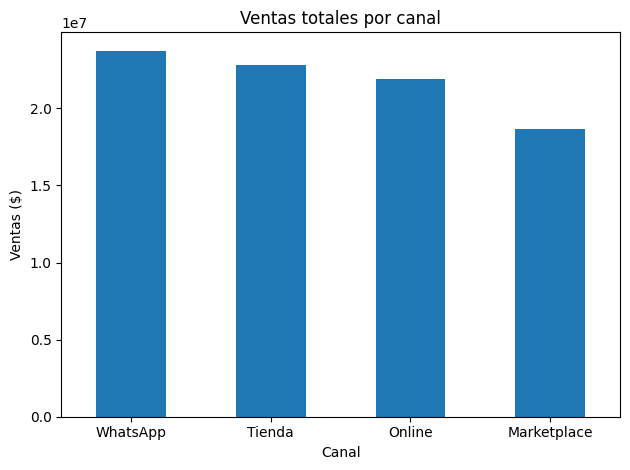

In [1023]:
ventas_canal.plot(kind="bar")

plt.title("Ventas totales por canal")
plt.xlabel("Canal")
plt.ylabel("Ventas ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [1024]:
ventas_categoria = (
    df_graficos
    .groupby("Categoría")["Total_Venta"]
    .sum()
    .sort_values(ascending=False)
)

ventas_categoria

,Total_Venta
Categoría,
Tecnología,52459695
Hogar,15455590
Belleza,11358915
Deportes,6035090
Oficina,1836580


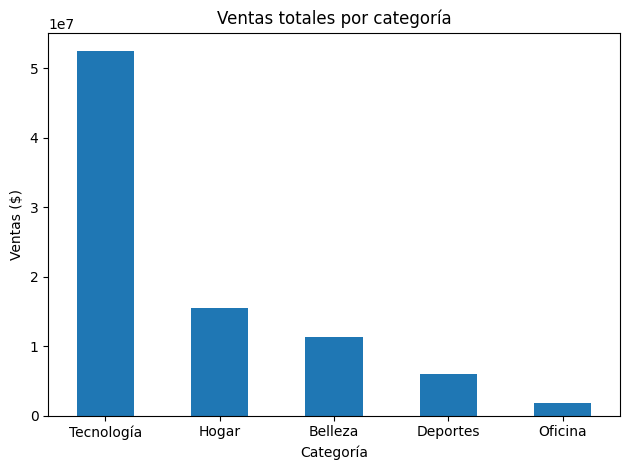

In [1025]:
ventas_categoria.plot(kind="bar")

plt.title("Ventas totales por categoría")
plt.xlabel("Categoría")
plt.ylabel("Ventas ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [1026]:
ventas_mes = (
    df_graficos.dropna(subset=["Fecha"])
    .groupby(df_graficos.dropna(subset=["Fecha"])["Fecha"].dt.to_period("M"))["Total_Venta"]
    .sum()
)

ventas_mes

,Total_Venta
Fecha,
2024-01,6006635
2024-02,7678790
2024-03,4447800
2024-04,7141330
2024-05,12113605
2024-06,4735745
2024-07,8684935
2024-08,10717325
2024-09,7411380


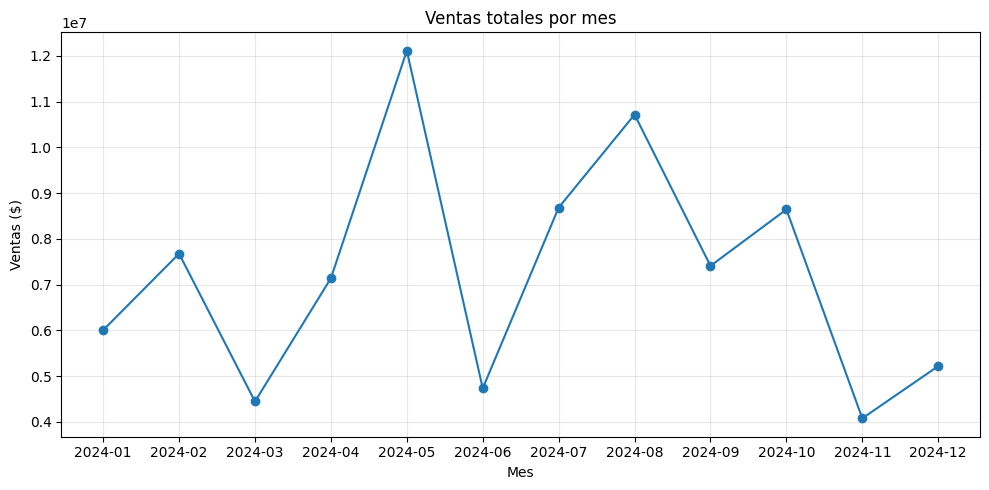

In [1027]:
ventas_mes.index = ventas_mes.index.astype(str)

plt.figure(figsize=(10, 5))
plt.plot(ventas_mes.index, ventas_mes.values, marker="o")

plt.title("Ventas totales por mes")
plt.xlabel("Mes")
plt.ylabel("Ventas ($)")
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [1028]:
top_productos = (
    df_graficos
    .groupby("Producto")["Total_Venta"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_productos

,Total_Venta
Producto,
Notebook,32272825
Monitor,13505085
Mesa,8166385
Plancha pelo,5257060
Impresora,4457475
Silla,3729635
Perfume,3233660
Mancuernas,2298470
Lámpara,2211340


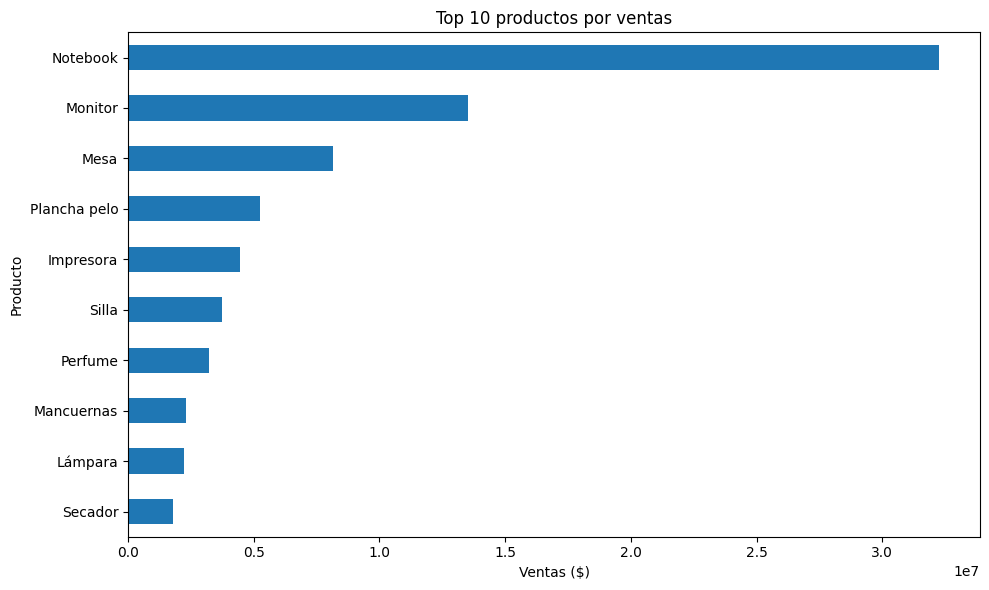

In [1029]:
plt.figure(figsize=(10, 6))

top_productos.sort_values().plot(kind="barh")

plt.title("Top 10 productos por ventas")
plt.xlabel("Ventas ($)")
plt.ylabel("Producto")
plt.tight_layout()
plt.show()

In [1030]:
print(f"\nRegistros totales en dataset: {len(df)}")
print(f"Registros para gráficos (sin originalmente vacíos, ni Canceladas/Devueltas): {len(df_graficos)}")
print(f"Registros excluidos de gráficos: {len(df) - len(df_graficos)}")
print(f"  - Originalmente vacíos: {df['Dato_Originalmente_Vacio'].sum()}")
print(f"  - Cancelados/Devueltos (sin contar los originalmente vacíos): "
      f"{(~df['Dato_Originalmente_Vacio'] & df['Estado_Entrega'].isin(['Cancelado', 'Devuelto'])).sum()}")


Registros totales en dataset: 646
Registros para gráficos (sin originalmente vacíos, ni Canceladas/Devueltas): 533
Registros excluidos de gráficos: 113
  - Originalmente vacíos: 12
  - Cancelados/Devueltos (sin contar los originalmente vacíos): 101


In [1031]:
# Base de rentabilidad: sin ventas canceladas ni devueltas
# (df_graficos ya viene sin ellas; el filtro se deja igual por claridad, no cambia el resultado)
df_rent = df_graficos[~df_graficos["Estado_Entrega"].isin(["Cancelado", "Devuelto"])].copy()

# Costo_Unitario * Unidades, para que el costo tenga el mismo signo que Total_Venta,
# se calcula con las Unidades tal como vienen. Así una venta con unidades negativas
# no genera un margen artificialmente negativo (venta negativa menos costo positivo).
df_rent["Costo_Total"] = df_rent["Costo_Unitario"] * df_rent["Unidades"]
df_rent["Margen"] = df_rent["Total_Venta"] - df_rent["Costo_Total"]
df_rent["Margen_%"] = (df_rent["Margen"] / df_rent["Total_Venta"] * 100).replace([np.inf, -np.inf], np.nan)

print(f"Registros usados para rentabilidad: {len(df_rent)} de {len(df_graficos)}")
df_rent[["ID_Venta", "Producto", "Total_Venta", "Costo_Total", "Margen", "Margen_%"]].head()

Registros usados para rentabilidad: 533 de 533


,ID_Venta,Producto,Total_Venta,Costo_Total,Margen,Margen_%
0,V-0001,Notebook,767040,719600,47440,6.184814
1,V-0002,Secador,38760,23500,15260,39.370485
2,V-0003,Silla,40230,27400,12830,31.891623
4,V-0005,Archivador,8600,4200,4400,51.162791
5,V-0006,Crema facial,26600,9200,17400,65.413534


In [1032]:
#Indicadores Generales
ventas_totales = df_rent["Total_Venta"].sum()
costo_total = df_rent["Costo_Total"].sum()
margen_total = df_rent["Margen"].sum()
margen_pct_total = margen_total / ventas_totales * 100
ticket_promedio = df_rent["Total_Venta"].mean()

print(f"Ventas totales:  ${ventas_totales:,.0f}")
print(f"Costo total:     ${costo_total:,.0f}")
print(f"Margen total:    ${margen_total:,.0f}")
print(f"Margen %:        {margen_pct_total:.1f}%")
print(f"Ticket promedio: ${ticket_promedio:,.0f}  (venta promedio por transacción)")

Ventas totales:  $87,145,870
Costo total:     $61,218,100
Margen total:    $25,927,770
Margen %:        29.8%
Ticket promedio: $163,501  (venta promedio por transacción)


In [1033]:
def resumen_rentabilidad(columna):
    r = df_rent.groupby(columna).agg(
        Ventas=("Total_Venta", "sum"),
        Costo=("Costo_Total", "sum"),
        Margen=("Margen", "sum"),
    )
    r["Margen_%"] = (r["Margen"] / r["Ventas"] * 100).round(1)
    r["Ranking_Ventas"] = r["Ventas"].rank(ascending=False, method="min").astype(int)
    r["Ranking_Margen"] = r["Margen"].rank(ascending=False, method="min").astype(int)
    return r.sort_values("Ventas", ascending=False)

rent_categoria = resumen_rentabilidad("Categoría")
rent_categoria

,Ventas,Costo,Margen,Margen_%,Ranking_Ventas,Ranking_Margen
Categoría,,,,,,
Tecnología,52459695,39339100,13120595,25.0,1,1
Hogar,15455590,9969200,5486390,35.5,2,2
Belleza,11358915,7463300,3895615,34.3,3,3
Deportes,6035090,3448900,2586190,42.9,4,4
Oficina,1836580,997600,838980,45.7,5,5


In [1034]:
rent_producto = resumen_rentabilidad("Producto")
rent_producto.head(10)

,Ventas,Costo,Margen,Margen_%,Ranking_Ventas,Ranking_Margen
Producto,,,,,,
Notebook,32272825,26009400,6263425,19.4,1,1
Monitor,13505085,8535000,4970085,36.8,2,2
Mesa,8166385,5481100,2685285,32.9,3,3
Plancha pelo,5257060,3676200,1580860,30.1,4,4
Impresora,4457475,3441500,1015975,22.8,5,7
Silla,3729635,2451400,1278235,34.3,6,5
Perfume,3233660,2130100,1103560,34.1,7,6
Mancuernas,2298470,1417900,880570,38.3,8,9
Lámpara,2211340,1316000,895340,40.5,9,8


In [1035]:
rent_canal = resumen_rentabilidad("Canal")
rent_canal

,Ventas,Costo,Margen,Margen_%,Ranking_Ventas,Ranking_Margen
Canal,,,,,,
WhatsApp,23747120,17087700,6659420,28.0,1,2
Tienda,22836105,15858100,6978005,30.6,2,1
Online,21927080,15706300,6220780,28.4,3,3
Marketplace,18635565,12566000,6069565,32.6,4,4


In [1036]:
rent_sucursal = resumen_rentabilidad("Sucursal")
rent_sucursal

,Ventas,Costo,Margen,Margen_%,Ranking_Ventas,Ranking_Margen
Sucursal,,,,,,
La Serena,14096280,9948800,4147480,29.4,1,1
Santiago Centro,12672790,8582900,4089890,32.3,2,2
Temuco,11889805,8753200,3136605,26.4,3,4
Las Condes,10838665,7676900,3161765,29.2,4,3
Providencia,10203940,7070500,3133440,30.7,5,5
Concepción,9544570,6900400,2644170,27.7,6,8
Viña del Mar,9213240,6430500,2782740,30.2,7,7
Antofagasta,8686580,5854900,2831680,32.6,8,6


In [1037]:
rent_vendedor = resumen_rentabilidad("Vendedor")
rent_vendedor

,Ventas,Costo,Margen,Margen_%,Ranking_Ventas,Ranking_Margen
Vendedor,,,,,,
Cristóbal León,17438395,13131600,4306795,24.7,1,1
Camila Rojas,13095420,9275600,3819820,29.2,2,4
Ignacio Pérez,12656675,8767600,3889075,30.7,3,2
Diego Muñoz,12405705,8534500,3871205,31.2,4,3
Fernanda Díaz,9390650,6262000,3128650,33.3,5,5
Valentina Soto,9080135,6515800,2564335,28.2,6,6
Felipe Torres,6769225,4778500,1990725,29.4,7,8
Martina Silva,6309665,3952500,2357165,37.4,8,7


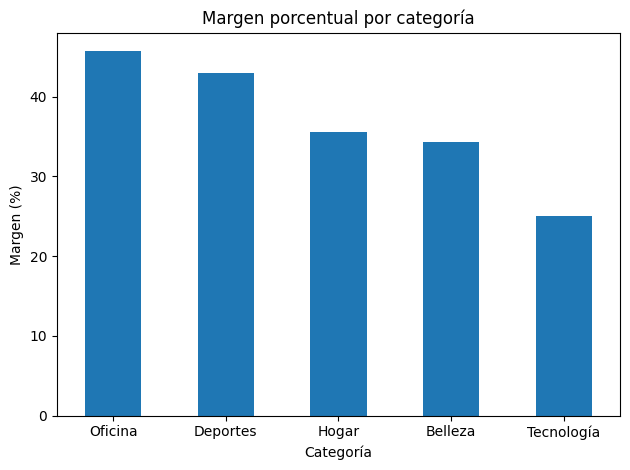

In [1038]:
rent_categoria["Margen_%"].sort_values(ascending=False).plot(kind="bar")

plt.title("Margen porcentual por categoría")
plt.xlabel("Categoría")
plt.ylabel("Margen (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [1039]:
ventas_producto = df_graficos.groupby("Producto")["Total_Venta"].sum()

part_categoria = ventas_categoria / ventas_categoria.sum() * 100
part_producto = ventas_producto / ventas_producto.sum() * 100
part_canal = ventas_canal / ventas_canal.sum() * 100

mes_max, mes_min = ventas_mes.idxmax(), ventas_mes.idxmin()
veces_mes = ventas_mes.max() / ventas_mes.min()

print(f"1. Categoría líder: {part_categoria.idxmax()} con {part_categoria.max():.1f}% de las ventas.")
print(f"2. Producto líder: {part_producto.idxmax()} con {part_producto.max():.1f}% de las ventas.")
print(f"3. Mes más alto: {mes_max}; mes más bajo: {mes_min}. El mejor mes vende {veces_mes:.1f} veces el peor.")
print("4. Participación por canal:")
print(part_canal.round(1).to_string())

1. Categoría líder: Tecnología con 60.2% de las ventas.
2. Producto líder: Notebook con 37.0% de las ventas.
3. Mes más alto: 2024-05; mes más bajo: 2024-11. El mejor mes vende 3.0 veces el peor.
4. Participación por canal:
Canal
WhatsApp       27.2
Tienda         26.2
Online         25.2
Marketplace    21.4


In [1040]:
base = df_graficos.dropna(subset=["Fecha"]).copy()
base["Mes"] = base["Fecha"].dt.to_period("M").astype(str)
# se usan mes_max y mes_min (calculados en la celda anterior). Con el recálculo de Total_Venta
comp = base[base["Mes"].isin([mes_max, mes_min])]

# 1) ¿Más ventas o ventas más caras?
comp.groupby("Mes").agg(
    Ventas=("Total_Venta", "sum"),
    N_ventas=("ID_Venta", "count"),
    Ticket_promedio=("Total_Venta", "mean"),
)

,Ventas,N_ventas,Ticket_promedio
Mes,,,
2024-05,12113605,50,242272.100000
2024-11,4079550,42,97132.142857


In [1042]:
# 2) ¿Qué productos explican la diferencia?
comp.pivot_table(index="Producto", columns="Mes", values="Total_Venta",
                 aggfunc="sum", fill_value=0).sort_values(mes_max, ascending=False)

Mes,2024-05,2024-11
Producto,,
Notebook,7429000,538380
Monitor,1794160,0
Silla,729010,316130
Plancha pelo,484380,594580
Mancuernas,300300,426965
Lámpara,258130,141825
Mesa,201780,278400
Teclado,133220,129320
Balón,114330,146040


### Hallazgos

1. **Alta dependencia de una categoría y de un producto.** Tecnología concentra cerca del 60% de las ventas y Notebook, por sí solo, el 37%. *Consecuencia:* el resultado del año depende de muy pocos productos, por lo que conviene vigilar su disponibilidad y su precio e impulsar venta de otras categorias que permitan una cartera diversificada.
2. **Estacionalidad marcada.** Mayo, el mes mas alto, vendió tres veces más que noviembre, el mas bajo, asociado al ticket medio (mayo $242.000 vs noviembre $97.000) principalmente por compra de Notebook y monitor.
3. **Canales con participación similar.** WhatsApp presenta el mayor monto de ventas (27,2%)con montos relativamente cercanos en cada canal entre (21,4% y 26,2%) lo que demuestra una buena competitividad.
4. **Rentabilidad.** A pesar de ser Tecnología la categoria con mayor venta, su margen es de 27,2% y el mayor margen se concentra en la categoria Oficina con 45,7% seguida de deportes con 42,9% por lo que conviene potenciarlas.



## Recomendaciones
1. Reducir la dependencia de Tecnología y de Notebook, impulsar las categorías con mayor margen porcentual(Oficina y deporte) y asegurar stock y condiciones de compra del producto líder.
2. Realizar campañas online y promociones de retiro en tienda que permitan aumentar las ventas al momento de retirar un producto.
3. Monitorear estacionalidad, el mes de mayo vendió casi 3 veces mas que noviembre, impulsada principalmente por el producto Notebook y Monitor. puede estar asociado a una campaña especial dado que no es un comportamiento normal en el resto de los meses.